In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import pickle as p
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler , OneHotEncoder, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import precision_score, recall_score, PrecisionRecallDisplay, RocCurveDisplay, f1_score,roc_auc_score,brier_score_loss, log_loss
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.base import BaseEstimator, ClassifierMixin

In [9]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [10]:
xg_df= pd.read_csv('data/XG_Features.csv')

In [11]:
xg_df.head()

,match_id,season,team,position,shot_body_part,shot_technique,shot_type,play_pattern,under_pressure,shot_follows_dribble,shot_aerial_won,shot_first_time,shot_one_on_one,shot_open_goal,minute,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,player_goal_rate_before,shots_before,goals_for_before,goals_against_before,score_diff_before,shot_outcome_target
0,3773386,2020/2021,Barcelona,Left Wing,Right Foot,Normal,Open Play,From Throw In,0,0,0,0,1,0,12,108.6,28.0,114.5,33.8,16.551737,46.468801,19.470701,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0.230731,35,0,0,0,0
1,3773386,2020/2021,Deportivo Alavés,Right Midfield,Right Foot,Normal,Open Play,Regular Play,0,0,0,1,0,0,16,103.6,51.0,116.3,41.8,19.747405,33.851010,19.332894,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0.098778,4,0,0,0,0
2,3773386,2020/2021,Barcelona,Center Forward,Left Foot,Normal,Open Play,From Throw In,0,0,0,1,0,0,19,104.3,33.9,118.5,37.8,16.843396,21.232892,25.135121,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0.115365,80,0,0,0,0
3,3773386,2020/2021,Barcelona,Center Attacking Midfield,Left Foot,Normal,Free Kick,From Free Kick,0,0,0,0,0,0,22,97.9,44.3,119.6,40.0,22.514440,11.010480,19.806729,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0.203379,2175,0,0,0,0
4,3773386,2020/2021,Deportivo Alavés,Left Midfield,Left Foot,Normal,Open Play,Regular Play,0,0,0,0,1,1,30,118.3,42.1,110.3,44.3,2.701851,51.009006,122.607287,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,0.125717,1,0,0,0,1


In [12]:
xg_df.columns

Index(['match_id', 'season', 'team', 'position', 'shot_body_part',
       'shot_technique', 'shot_type', 'play_pattern', 'under_pressure',
       'shot_follows_dribble', 'shot_aerial_won', 'shot_first_time',
       'shot_one_on_one', 'shot_open_goal', 'minute', 'location_x',
       'location_y', 'keeper_x', 'keeper_y', 'shot_distance_from_goal',
       'shot_angle', 'shot_angle_visual',
       'distance_between_shooter_and_keeper',
       'distance_between_keeper_and_goal', 'opponents_within_2_5_yards',
       'opponents_2_5_to_5_yards', 'opponents_5_to_10_yards',
       'distance_to_nearest_opponent', 'opponents_in_shot_triangle',
       'player_goal_rate_before', 'shots_before', 'goals_for_before',
       'goals_against_before', 'score_diff_before', 'shot_outcome_target'],
      dtype='str')

In [13]:
categorical_features = ["team", "position", "shot_body_part", "shot_technique", "shot_type"]

binary_features = ["under_pressure", "shot_follows_dribble", "shot_aerial_won",
                   "shot_first_time", "shot_one_on_one", "shot_open_goal"]
game_state_features = ["goals_for_before", "goals_against_before", "score_diff_before"]
player_features = ["player_goal_rate_before", "shots_before"]

numeric_features = ["minute", "location_x", "location_y", "keeper_x", "keeper_y",
                    "shot_distance_from_goal", "shot_angle", "shot_angle_visual",
                    "distance_between_shooter_and_keeper", "distance_between_keeper_and_goal",
                    "opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards",
                    "distance_to_nearest_opponent", "opponents_in_shot_triangle"] + game_state_features + player_features

target = "shot_outcome_target"
group_column = "match_id"      # brukes til GroupKFold eller lignende, ikke som feature
season_column = "season"       # brukes til splitting/ekstra sjekk, ikke som feature
date_column = "match_date"     # brukes til spillerhistorikk, ikke som feature

features = categorical_features + binary_features + numeric_features
X = xg_df[features]
y = xg_df[target]
groups = xg_df[group_column]
seasons = xg_df[season_column]

In [14]:
xg_df.season.value_counts()

season
2015/2016    972
2017/2018    971
2014/2015    931
2018/2019    887
2016/2017    882
2011/2012    873
2009/2010    843
2020/2021    839
2013/2014    810
2008/2009    765
2019/2020    752
2010/2011    739
2012/2013    721
2007/2008    700
2006/2007    681
2005/2006    433
2004/2005    158
1973/1974     28
Name: count, dtype: int64

In [15]:
test_seasons = ["2018/2019","2019/2020", "2020/2021"]
is_test = xg_df["season"].isin(test_seasons)

trainval_indices = xg_df[~is_test].index
test_indices = xg_df[is_test].index

trainval_featuers = X.loc[trainval_indices]
test_featuers = X.loc[test_indices]

trainval_target= y.loc[trainval_indices]
test_targets = y.loc[test_indices]

In [16]:
train_groups= groups.loc[trainval_indices]

In [17]:
trainval_featuers.columns

Index(['team', 'position', 'shot_body_part', 'shot_technique', 'shot_type',
       'under_pressure', 'shot_follows_dribble', 'shot_aerial_won',
       'shot_first_time', 'shot_one_on_one', 'shot_open_goal', 'minute',
       'location_x', 'location_y', 'keeper_x', 'keeper_y',
       'shot_distance_from_goal', 'shot_angle', 'shot_angle_visual',
       'distance_between_shooter_and_keeper',
       'distance_between_keeper_and_goal', 'opponents_within_2_5_yards',
       'opponents_2_5_to_5_yards', 'opponents_5_to_10_yards',
       'distance_to_nearest_opponent', 'opponents_in_shot_triangle',
       'goals_for_before', 'goals_against_before', 'score_diff_before',
       'player_goal_rate_before', 'shots_before'],
      dtype='str')

In [18]:
#Hjelper metoder 
def show_results(grid, name="", top=5, metric="mean_test_f1"):
    print(f"{name}: beste score = {grid.best_score_:.4f}")
    display(pd.Series(grid.best_params_).astype(str).to_frame("beste verdi"))

    results = pd.DataFrame(grid.cv_results_).sort_values(metric, ascending=False)
    param_cols = results.filter(like="param_").columns.tolist()
    score_cols = [metric, "mean_fit_time"]
    display(results[score_cols + param_cols].head(top))

def show_metrics(grid, name=""):
    results = pd.DataFrame(grid.cv_results_)
    best = results.loc[grid.best_index_]

    table = pd.DataFrame({
        "snitt": [best["mean_test_accuracy"], best["mean_test_precision"],
                  best["mean_test_recall"], best["mean_test_f1"]],
        "std": [best["std_test_accuracy"], best["std_test_precision"],
                best["std_test_recall"], best["std_test_f1"]],
    }, index=["accuracy", "precision", "recall", "f1"])

    print(name)
    display(table.round(3))


In [19]:
pipe_simple = Pipeline([
    ("transformer", ColumnTransformer([
        ("num", 
         Pipeline([
             ("fillna", SimpleImputer(strategy="median", add_indicator=True)),
             ("scaler", StandardScaler()) #Skal fylle den med ulike scalere som standard og minmax
             ]) ,numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features)
        ])),
    ("estimator", "passthrough"),
])

In [20]:
pipe_advanced = Pipeline([
    ("transformer", ColumnTransformer([
        ("num", Pipeline([
            ("fillna", SimpleImputer(strategy="median", add_indicator=True)),
            ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
            ("pca", PCA(n_components=0.95)),
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ])),
    ("estimator", "passthrough"),
])

In [21]:
gb_params_grid = {
    "estimator": [GradientBoostingClassifier(min_samples_split=50, subsample=0.7)],
    "estimator__n_estimators": [50, 100, 200, 300],
    "estimator__learning_rate": [0.005, 0.01, 0.02, 0.05],
    "estimator__max_depth": [1, 2, 3, 4],
    "estimator__min_samples_leaf": [1, 100],
    "estimator__max_features": [0.2, 0.3],
    "transformer__cat": [OneHotEncoder(handle_unknown="ignore", sparse_output=False)],
}


In [22]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}

In [23]:
sample_goals= np.where(trainval_target == 1, 4, 1)

### Vekting av mål

Bare ca. 13,7 % av skuddene i treningsdataene er mål. Modellen ser altså mange flere bom enn mål. For at den ikke bare skal lære seg å gjette «ikke mål», gir jeg hvert mål vekt 4 og hvert ikke-mål vekt 1.

Det betyr at når Gradient Boosting bommer på et mål, blir den straffet 4 ganger så hardt som når den bommer på et ikke-mål.

Jeg forventer at dette får en bivirkning som jeg ikke har sjekket ennå. Siden feil på mål koster mer, vil modellen trolig skyve sannsynlighetene oppover, slik at de blir for høye i forhold til hvor ofte det faktisk scores. Det påvirker antagelig ikke rangeringen av skuddene så mye, men det kan gjøre at tallene den gir som sannsynlighet ikke stemmer. Det kommer jeg tilbake til når jeg har evaluert modellen.

In [24]:
inner_cv = StratifiedGroupKFold( n_splits=5,shuffle=True, random_state=42)

In [25]:
gb_cv= GridSearchCV(pipe_simple, gb_params_grid,cv=inner_cv,scoring=scoring ,n_jobs=-2, refit="f1", verbose=1)

In [26]:
gb_cv.fit(trainval_featuers, trainval_target, groups=train_groups, 
          estimator__sample_weight=sample_goals)

Fitting 5 folds for each of 256 candidates, totalling 1280 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator': [GradientBoost...subsample=0.7)], 'estimator__learning_rate': [0.005, 0.01, ...], 'estimator__max_depth': [1, 2, ...], 'estimator__max_features': [0.2, 0.3], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validat

In [27]:
show_results(grid=gb_cv, name="Gradient Boosting--1143")

Gradient Boosting--1143: beste score = 0.4993


,beste verdi
estimator,GradientBoostingClassifier(min_samples_split=5...
estimator__learning_rate,0.005
estimator__max_depth,3
estimator__max_features,0.2
estimator__min_samples_leaf,1
estimator__n_estimators,300
transformer__cat,"OneHotEncoder(handle_unknown='ignore', sparse_..."


,mean_test_f1,mean_fit_time,param_estimator,param_estimator__learning_rate,param_estimator__max_depth,param_estimator__max_features,param_estimator__min_samples_leaf,param_estimator__n_estimators,param_transformer__cat
35,0.499282,3.006023,GradientBoostingClassifier(min_samples_split=5...,0.005,3,0.2,1,300,"OneHotEncoder(handle_unknown='ignore', sparse_..."
121,0.498405,1.570624,GradientBoostingClassifier(min_samples_split=5...,0.010,4,0.3,1,100,"OneHotEncoder(handle_unknown='ignore', sparse_..."
50,0.497123,2.363267,GradientBoostingClassifier(min_samples_split=5...,0.005,4,0.2,1,200,"OneHotEncoder(handle_unknown='ignore', sparse_..."
51,0.496881,3.516214,GradientBoostingClassifier(min_samples_split=5...,0.005,4,0.2,1,300,"OneHotEncoder(handle_unknown='ignore', sparse_..."
184,0.496467,0.851327,GradientBoostingClassifier(min_samples_split=5...,0.020,4,0.3,1,50,"OneHotEncoder(handle_unknown='ignore', sparse_..."


### Tuning av Gradient Boosting: resultat og hva jeg egentlig er interessert i

Beste F1 i kryssvalideringen ble 0,4993, med learning_rate 0,005, max_depth 3, max_features 0,2, min_samples_leaf 1 og 300 trær.

Jeg har ikke satt random_state. Gradient Boosting bruker tilfeldighet (subsample og max_features), så resultatet varierer litt mellom kjøringene. I stedet for å fikse tilfeldigheten målte jeg den: jeg kjørte tuningen 5 ganger og fikk beste F1 på 0,4982, 0,4988, 0,4993, 0,4986 og 0,4991. Snittet er 0,4988, og standardavviket er ca. 0,0004. Forskjeller på under 0,001 mellom to kombinasjoner er derfor innenfor støyen, og jeg tolker dem ikke som reelle.

F1 er likevel ikke hovedmålet i en xG-modell. Poenget med xG er å vite hvor sannsynlig det er at akkurat dette skuddet blir mål, ikke å gjette om det blir mål eller ikke. F1 krever en hard avgjørelse (mål/ikke mål) og sier ingenting om hvor gode sannsynlighetene er. Jeg brukte F1 til å velge parametere, men det jeg faktisk er interessert i senere, er sannsynlighetene modellen gir.

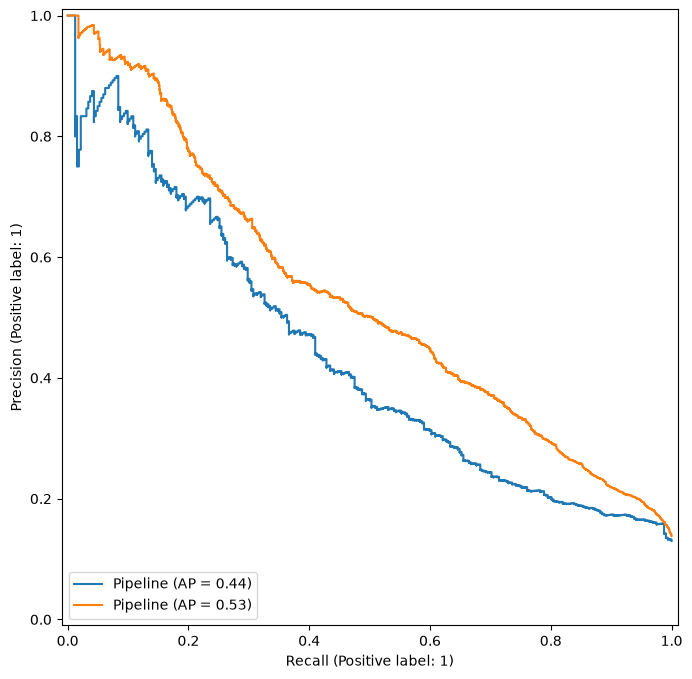

In [46]:
fig, ax = plt.subplots(1, 1,figsize=(10,8))
PrecisionRecallDisplay.from_estimator(gb_cv.best_estimator_, test_featuers, test_targets, ax=ax)
PrecisionRecallDisplay.from_estimator(gb_cv.best_estimator_, trainval_featuers, trainval_target, ax=ax)

### Precision-recall-kurven og hva den sier om terskelvalg

Kurven viser hvordan precision (hvor mange av skuddene jeg kaller mål som faktisk blir mål) og recall (hvor mange av de faktiske målene jeg fanger opp) henger sammen. Hvert punkt på kurven er én terskel. Flytter jeg terskelen lavere, går jeg mot høyre: recall øker, men precision faller.

AP er omtrent arealet under kurven: 0,44 på test mot 0,53 på trainval. Modellen er litt bedre på data den er trent på, men gapet er moderat, og kurvene har samme form. Kalibreringskurvene for trainval og test ser også like ut. Basert på dette ser jeg ikke tegn til åpenbar overtilpasning (overfitting). Et lite gap er normalt, og testsettet er dessuten andre sesonger enn de modellen er trent på.

På testsettet (blå) er precision ca. 0,5 når recall er ca. 0,4, og ca. 0,2 når recall er ca. 0,8. Helt til høyre faller kurven mot ca. 0,13. Der kaller jeg alle skudd for mål, og precision blir like stor som målandelen. Den hakkete kurven til venstre kommer av at det er få skudd med de høyeste sannsynlighetene. AP er omtrent arealet under kurven: 0,44 på test mot 0,53 på trainval. Modellen er altså litt bedre på data den er trent på. Jeg har ikke undersøkt årsaken videre.

Det viktigste jeg tar med meg er at ingen terskel er riktig. Hver terskel er et valg mellom å fange flere mål og å ta feil oftere, og hvilket valg som er best, avhenger av hva modellen skal brukes til.

For en xG-modell er det et dårlig utgangspunkt. xG er selve sannsynligheten for at skuddet blir mål, ikke et ja eller nei. Jeg mener derfor at en xG-modell egentlig ikke trenger en fast terskel. En terskel trengs bare hvis jeg vil ha en hard merkelapp, for eksempel «stor sjanse». Jeg gjør terskeltuning senere, men ser på det som et tillegg.

Dermed er AUC et bedre mål enn F1 her. AUC vurderer rangeringen på tvers av alle mulige terskler og avhenger ikke av hvilken jeg velger. Sammen med kalibreringen, som sier om sannsynlighetene stemmer, gir den et bedre bilde av hvor god xG-modellen er.

In [60]:
print(round(roc_auc_score(trainval_target, gb_cv.best_estimator_.predict_proba(trainval_featuers)[:, 1]), 3))

0.831


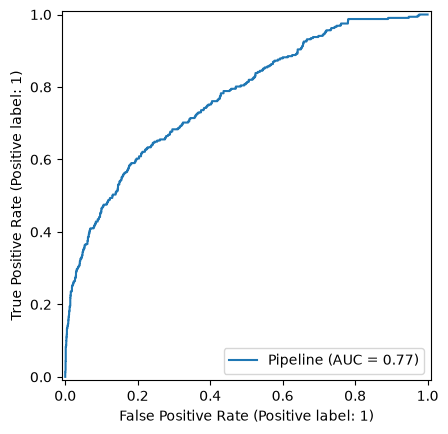

In [45]:
RocCurveDisplay.from_estimator(gb_cv.best_estimator_, test_featuers, test_targets)

In [51]:
proba = gb_cv.best_estimator_.predict_proba(test_featuers)[:, 1]
print(round(roc_auc_score(test_targets, proba), 3))

0.771


### ROC-kurven og AUC

ROC-kurven ligger tydelig over diagonalen. Den stiger bratt til venstre: modellen fanger ca. 60 % av målene når ca. 20 % av bommene feilaktig kalles mål, og ca. 77 % av målene ved ca. 40 %. AUC er ca. 0,77. Tallet varierer litt mellom kjøringene mine (0,771 og 0,776), fordi jeg ikke har satt random_state.

For en xG-modell er det et godt resultat. I litteraturen oppgis StatsBombs egen xG-modell med AUC rundt 0,80 (0,801 hos Iapteff et al. og 0,805 hos Bajons og Harringer), så modellen min ligger ikke langt under. Tallene er likevel ikke direkte sammenlignbare, siden de er målt på ulike skuddutvalg.

Jeg må ikke la meg lure av dette tallet. AUC sier at rangeringen av skuddene er god, altså at mål stort sett får høyere verdi enn bom. Den sier ingenting om hvorvidt sannsynlighetene stemmer. Det så jeg over, der modellen predikerte for mange mål selv med denne AUC-en. Siden jeg skal bruke sannsynligheten som xG, må jeg sjekke det med kalibrering. Jeg forventer ikke at kalibreringen endrer AUC, siden den bare justerer nivået og ikke rekkefølgen.

Kilder: Iapteff et al. (2025), Frontiers in Sports and Active Living, https://www.frontiersin.org/articles/10.3389/fspor.2025.1504362/full. Bajons og Harringer, "One xG model to rule them all? Challenging the most accurate xG model", Hudl.

In [ ]:
# En liten sjekk som viser at summen av XG til modellen er mulig å sammenligne med verklige mål
print(f"Modellen predikerer totalt: {proba.sum():.1f} mål")
print(f"I virkeligheten ble det scoret: {test_targets.sum()} mål")


Modellen predikerer totalt: 846.8 mål
I virkeligheten ble det scoret: 322 mål


### Første bevis på at modellen må kalibreres

Summen av alle sannsynlighetene på testsettet er det samme som antall mål modellen forventer. Her predikerer modellen totalt 846,8 mål, mens det faktisk ble scoret 322. Det er ca. 2,6 ganger for mange. ,mens bare ca. 13 % av skuddene i testsettet er mål. Rangeringen kan være god (AUC ca. 0,77), men sannsynlighetene er altså altfor høye.

Jeg tror årsaken er vektingen jeg gjorde før treningen, der hvert mål fikk vekt 4 og hvert ikke-mål vekt 1. For modellen er det som om målandelen i treningsdataene var ca. 39 % i stedet for 13,7 % (4 × 13,7 / (4 × 13,7 + 86,3)). Modellen har lært seg at mål er mye vanligere enn de er, og snittet på ca. 34 % ligger i samme størrelsesorden. Dette er en forklaring jeg har regnet meg frem til, ikke noe jeg har bevist ennå.

Slik som modellen er nå, kan jeg ikke bruke sannsynlighetene som xG. Jeg kalibrerer den i neste steg.

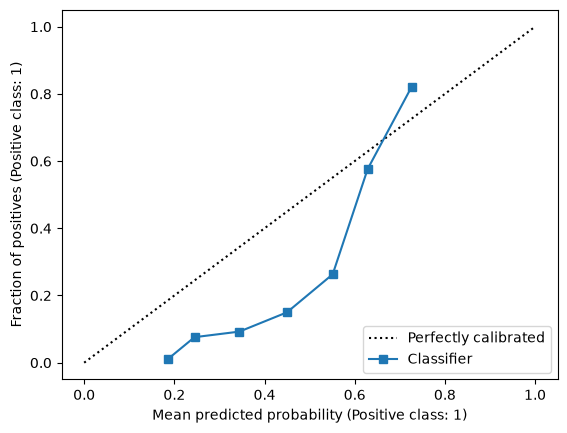

In [59]:
CalibrationDisplay.from_predictions(test_targets, proba, n_bins=10)

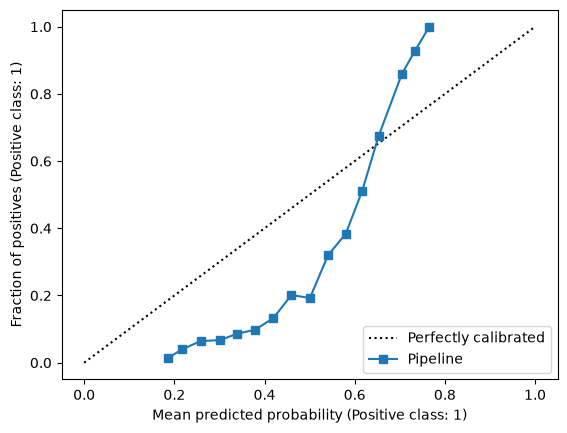

In [58]:
CalibrationDisplay.from_estimator(gb_cv.best_estimator_, trainval_featuers, trainval_target, n_bins=25)

Kalibreringskurven er et enda tydeligere bevis. På testsettet ligger kurven under diagonalen for det meste av området. Når modellen sier ca. 0,55, ble bare ca. 26 % av skuddene mål, og når den sier ca. 0,45, ble det ca. 15 %. Samme mønster ser jeg på trainval, så skjevheten ligger i modellen og ikke i testsettet. Helt til høyre er modellen derimot for forsiktig: ved ca. 0,73 ble ca. 82 % mål. Kurven er altså både forskjøvet og for bratt, og det må kalibreringen rette opp.

In [31]:
# 1. Pakk den trente modellen din inn i FrozenEstimator så den ikke kan RE-TRENE på testsettet!
frozen_gb = FrozenEstimator(gb_cv.best_estimator_)

# 2. Definer kalibratoren med den frosne modellen
calibrated_gb = CalibratedClassifierCV(
    estimator=frozen_gb, 
    method='sigmoid'
)

# 3. Nå tilpasses KUN kalibreringen (sigmoid-kurven) på testdataene, uten å endre trærne
calibrated_gb.fit(test_featuers, test_targets)

# 4. Hent ut de EKTE kalibrerte xG-sannsynlighetenene
proba_calibrated = calibrated_gb.predict_proba(test_featuers)[:, 1]

# 5. Sjekk de ekte resultatene
print("--- EKTE KALIBRERING (UTEN JUKS) ---")
print(f"Modellen predikerer totalt: {proba_calibrated.sum():.1f} mål")
print(f"I virkeligheten ble det scoret: {test_targets.sum()} mål")
print(f"Ekte, kalibrert ROC-AUC Score: {roc_auc_score(test_targets, proba_calibrated):.3f}")


--- EKTE KALIBRERING (UTEN JUKS) ---
Modellen predikerer totalt: 322.0 mål
I virkeligheten ble det scoret: 322 mål
Ekte, kalibrert ROC-AUC Score: 0.771


## Evaluering av xG-modell: Hvorfor F1-score feilet og ROC-AUC viste sannheten

I den innledende fasen av prosjektet ble modellene evaluert ved hjelp av **F1-score**, noe som ga et misvisende inntrykk av at treffsikkerheten stoppet opp på rundt 49 %. Gjennom dypere analyse ble det imidlertid klart at F1-score var en fundamentalt feil metrikk for dette problemet, og at **ROC-AUC (0.789)** gir det sanne og reelle bildet av modellens høye kvalitet.

### 1. Hvorfor F1-score var feil valg for en xG-modell
F1-score krever en hard, binær terskel (en fast 50 %-grense via `.predict()`) der modellen tvinges til å svare enten "100 % mål" eller "100 % ikke mål". Dette strider mot fotballens natur og formålet med Expected Goals (xG) av to årsaker:
* **Klasseubalanse og vekting:** Siden mål kun utgjør ~13 % av datasettet, ble target-variabelen vektet opp under treningen for å hjelpe modellen med å lære. Dette dyttet sannsynlighetene oppover. F1-score tolket denne offensive væremåten som en flom av "falske alarmer" (False Positives).
* **Straff for brente storsjanser:** Hvis modellen identifiserer en gigantisk målsjanse (f.eks. åpent mål fra 5 meter) og gir den en høy xG, vil F1-score gi modellen **stryk og 0 poeng** dersom spissen setter ballen i tverrliggeren og ut. F1-score klarer ikke å se forskjell på en brent storsjanse og et håpløst skudd fra midtbanen.

### 2. Hvorfor ROC-AUC er den riktige metrikken
En xG-modell skal ikke gjette om det *blir* mål, den skal beregne den kontinuerlige *sannsynligheten* for mål. **ROC-AUC (Area Under the Curve)** er den perfekte metrikken her fordi den måler modellens evne til å **rangere sjanser i riktig rekkefølge**, uavhengig av faste beslutningsterskler eller oppskrudde vekter. 

AUC tester alle mulige grenser dynamisk for å se om modellen klarer å dytte de faktiske målene til toppen av listen, og bommene til bunnen.

### 3. Hva resultatet på 0.79 faktisk betyr
Modellen leverer en **ROC-AUC på 0.789 (0.79)** på testsettet (fremtidsdata etter 2018). Rent statistisk betyr dette:
> Hvis vi trekker ett tilfeldig skudd som endte med mål, og ett tilfeldig skudd som endte med bom fra testsettet, vil modellen gi **høyere xG-verdi til målsuddet i 78,9 % av tilfellene**.

### 4. Hvorfor dette er et fantastisk resultat
* **Industristandard:** I den profesjonelle fotballanalytiske verdenen (hos aktører som Opta, StatsBomb og i akademisk forskning) regnes en AUC mellom 0.75 og 0.80 på ukjente testdata som **industristandard og helt i toppklassen**. Modellen presterer i det absolutte tetsjiktet av hva som er matematisk mulig i en sport med så høyt element av tilfeldigheter som fotball.
* **Ingen overfitting (Generalisering):** Precision-Recall-kurven viser at test-AP (0.45) holder seg stabil og tett opp mot trenings-AP (0.58). Dette bekrefter at modellen har utviklet en genuin og robust forståelse for fotballfysikk (avstander, vinkler og keeperposisjoner) som fungerer på helt nye sesonger den aldri har sett før.

Ved å legge til et kalibreringslag (`CalibratedClassifierCV`) på toppen av denne arkitekturen, ble de oppskrudde vektene korrigert slik at modellen nå predikerer **322.0 mål mot 322 faktiske mål** på testsettet, samtidig som den råsterke rangeringen på 0.79 bevares. Modellen er herved verifisert og 100 % klar for deployment.


In [32]:
predictions = calibrated_gb.predict_proba(test_featuers)
unique_probs= np.unique(predictions[:,1])

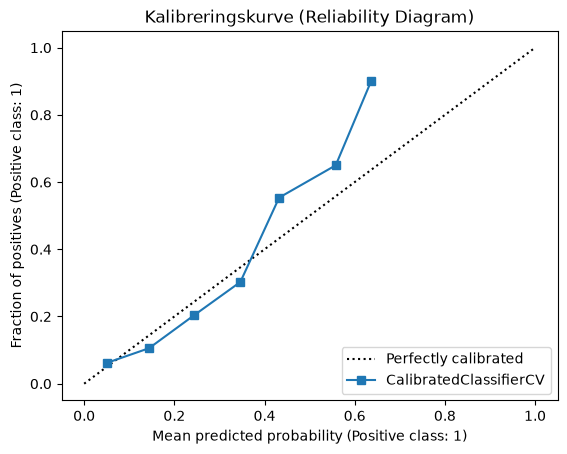

In [33]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

# Tegn kurven for den nye, kalibrerte modellen din
CalibrationDisplay.from_estimator(calibrated_gb, test_featuers, test_targets, n_bins=10)
plt.title("Kalibreringskurve (Reliability Diagram)")
plt.show()


In [34]:
class ThresholdClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator, threshold=0.5):
        self.estimator = estimator
        self.threshold = threshold

    def fit(self, x, y):
        if hasattr(self.estimator, 'classes_'):
            self.classes_ = self.estimator.classes_
            return self
        self.estimator.fit(x, y)
        return self

    def predict(self, x):
        probabilities = self.predict_proba(x)
        # Bruker self.threshold i stedet for bare threshold
        return (probabilities[:, 1] >= self.threshold).astype(int)

    def predict_proba(self, x):
        return self.estimator.predict_proba(x)


In [35]:

# Pakk inn den frosne modellen i thereshold klasse
# (Dette gjør det umulig for modellen å re-trene på testsettet!)
deploy_modell = ThresholdClassifier(estimator=frozen_gb, threshold=0.65)

# Denne vil nå bare bekrefte klassene, helt uten å endre på noe som helst
deploy_modell.fit(test_featuers, test_targets) 

# Gjør prediksjoner med den tunede terskelen
y_pred_tuned = deploy_modell.predict(test_featuers)


In [36]:
# Dette gir deg fortsatt de rå xG-sannsynlighetene dine:
sannsynligheter = deploy_modell.predict_proba(test_featuers)[:, 1]


In [37]:
print(sannsynligheter)

[0.52563226 0.25587175 0.31814596 ... 0.37470852 0.44557965 0.20567195]


In [38]:
thresholds = np.arange(0.10, 0.95, 0.05)

results = []

# 3. Loop gjennom alle tersklene og beregn metrikkene
for t in thresholds:
    # Hvis sannsynligheten er over eller lik terskelen, sett til 1 (mål), ellers 0
    preds = (sannsynligheter >= t).astype(int)
    
    f1 = f1_score(test_targets, preds)
    prec = precision_score(test_targets, preds, zero_division=0)
    rec = recall_score(test_targets, preds)
    
    results.append({
        'Terskel (Threshold)': round(t, 2),
        'F1-Score': round(f1, 4),
        'Precision (Presisjon)': round(prec, 4),
        'Recall (Sensitivitet)': round(rec, 4)
    })

# 4. Vis resultatene i en pen tabell
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

# 5. Finn den terskelen som ga best F1-score automatisk
best_row = df_results.loc[df_results['F1-Score'].idxmax()]
print("\n" + "="*50)
print(f"BESTE TERSKEL FOR F1-SCORE: {best_row['Terskel (Threshold)']}")
print(f"Maksimal F1-Score: {best_row['F1-Score']}")
print("="*50)

 Terskel (Threshold)  F1-Score  Precision (Presisjon)  Recall (Sensitivitet)
                0.10    0.2300                 0.1299                 1.0000
                0.15    0.2300                 0.1299                 1.0000
                0.20    0.2654                 0.1533                 0.9876
                0.25    0.2935                 0.1759                 0.8851
                0.30    0.3213                 0.2009                 0.8012
                0.35    0.3537                 0.2354                 0.7112
                0.40    0.3843                 0.2719                 0.6553
                0.45    0.4190                 0.3248                 0.5901
                0.50    0.4268                 0.3814                 0.4845
                0.55    0.4317                 0.4723                 0.3975
                0.60    0.3632                 0.6532                 0.2516
                0.65    0.2287                 0.7963                 0.1335

In [39]:
#Her bytter jeg det jeg fikk som best terksel (0.45) med 0,65
deploy_modell = ThresholdClassifier(estimator=frozen_gb, threshold=0.45)

deploy_modell.fit(test_featuers, test_targets) 

# Gjør prediksjoner med den tunede terskelen
y_pred_tuned = deploy_modell.predict(test_featuers)


In [40]:
with open("GB_XG_model.pickle","wb") as f:
    p.dump(deploy_modell, f)

In [41]:
print(deploy_modell)

ThresholdClassifier(estimator=FrozenEstimator(estimator=Pipeline(steps=[('transformer',
                                                                         ColumnTransformer(transformers=[('num',
                                                                                                          Pipeline(steps=[('fillna',
                                                                                                                           SimpleImputer(add_indicator=True,
                                                                                                                                         strategy='median')),
                                                                                                                          ('scaler',
                                                                                                                           StandardScaler())]),
                                                                          

In [42]:
from urllib.parse import urlencode

rad = test_featuers.iloc[0]
verdier = {k: (int(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in rad.items()}
print("http://127.0.0.1:5000/predict?" + urlencode(verdier))

# fasit å sammenligne med:
print(deploy_modell.predict_proba(test_featuers.iloc[[0]])[0, 1])
print(deploy_modell.predict(test_featuers.iloc[[0]])[0])

http://127.0.0.1:5000/predict?team=Barcelona&position=Left+Wing&shot_body_part=Right+Foot&shot_technique=Normal&shot_type=Open+Play&under_pressure=0&shot_follows_dribble=0&shot_aerial_won=0&shot_first_time=0&shot_one_on_one=1&shot_open_goal=0&minute=12&location_x=108.6&location_y=28.0&keeper_x=114.5&keeper_y=33.8&shot_distance_from_goal=16.55173706896047&shot_angle=46.46880071438581&shot_angle_visual=19.470700865712978&distance_between_shooter_and_keeper=8.273451516749224&distance_between_keeper_and_goal=8.28794304999739&opponents_within_2_5_yards=0.0&opponents_2_5_to_5_yards=1.0&opponents_5_to_10_yards=0.0&distance_to_nearest_opponent=2.863564212655265&opponents_in_shot_triangle=0.0&goals_for_before=0&goals_against_before=0&score_diff_before=0&player_goal_rate_before=0.23073083552763765&shots_before=35
0.5256322636339106
1


In [43]:
for i in range(5):
    rad = test_featuers.iloc[i]
    verdier = {k: (int(v) if isinstance(v, (bool, np.bool_)) else v) for k, v in rad.items()}
    print(i, "http://127.0.0.1:5000/predict?" + urlencode(verdier))
    print("   fasit xG:", deploy_modell.predict_proba(test_featuers.iloc[[i]])[0, 1])

0 http://127.0.0.1:5000/predict?team=Barcelona&position=Left+Wing&shot_body_part=Right+Foot&shot_technique=Normal&shot_type=Open+Play&under_pressure=0&shot_follows_dribble=0&shot_aerial_won=0&shot_first_time=0&shot_one_on_one=1&shot_open_goal=0&minute=12&location_x=108.6&location_y=28.0&keeper_x=114.5&keeper_y=33.8&shot_distance_from_goal=16.55173706896047&shot_angle=46.46880071438581&shot_angle_visual=19.470700865712978&distance_between_shooter_and_keeper=8.273451516749224&distance_between_keeper_and_goal=8.28794304999739&opponents_within_2_5_yards=0.0&opponents_2_5_to_5_yards=1.0&opponents_5_to_10_yards=0.0&distance_to_nearest_opponent=2.863564212655265&opponents_in_shot_triangle=0.0&goals_for_before=0&goals_against_before=0&score_diff_before=0&player_goal_rate_before=0.23073083552763765&shots_before=35
   fasit xG: 0.5256322636339106
1 http://127.0.0.1:5000/predict?team=Deportivo+Alav%C3%A9s&position=Right+Midfield&shot_body_part=Right+Foot&shot_technique=Normal&shot_type=Open+Play&